# Scientific Claim Verification Using Dense Retrieval, Evidence Extraction, and Natural Language Inference

**NLP semester project · two-person team · reproducible experimental report**

## Abstract

We study scientific claim verification on the official SciFact corpus using lexical retrieval, pretrained
sentence embeddings, task-specific contrastive fine-tuning, hybrid rank fusion, and neural reranking.
A trained sentence selector and binary stance classifier provide evidence and SUPPORT/CONTRADICT predictions;
the pipeline abstains when relevance filters reject all evidence. Oracle interventions diagnose retrieval
and evidence-selection losses. This notebook executes each stage and reports measured results, including
the unmodified official SciFact metrics. The supplied run uses the complete data with MiniLM retrieval and SciBERT on GPU;
larger GPU and repeated-seed configurations are available. Smoke experiments are explicitly excluded from findings.

Outputs below are produced by code, never inserted illustrative scores. The final discussion is generated
from the saved evaluation artifacts so it stays consistent with the selected execution configuration.

## 1. Configuration and reproducibility

Run from the repository root. Locally, create the virtual environment described in README.md and select its
kernel. In Colab, upload/clone this complete directory, change to its root, and install requirements first
(`%pip install -r requirements.txt`), then restart the runtime. GPU detection is automatic.

`MODE='full'` is the intended research path. `smoke` checks the whole workflow using 40 training claims,
16 validation claims, 16 dev claims, and a reduced corpus. `extended` allows longer training; run
`scripts/run_seeded.py` for three seeds on the same split. A run directory is immutable with respect to its
configuration: choose a new directory when changing hyperparameters. Re-execution reuses checkpoints and caches.

In [1]:
from pathlib import Path
import os, sys, json
assert Path('scifact_project').is_dir(), 'Change working directory to the project root first.'
from scifact_project.config import Config
MODE = 'full'
PROFILE = 'auto'                 # cpu uses MiniLM pair models; gpu uses SciBERT
SEED = 42
config = Config.for_mode(MODE, PROFILE, SEED).prepare()
from scifact_project.experiment import Study
study = Study(config)
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
pd.set_option('display.max_columns', 16)
display(pd.DataFrame([config.dictionary()]).T.rename(columns={0: 'value'}))
display(Markdown(f'Actual device: **{config.device}**. Mode: **{MODE}**. Results: `{config.output_dir}`.'))

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
mode,full
profile,gpu
seed,42
split_seed,42
data_dir,data/raw/data
output_dir,outputs/full_gpu_seed42
dense_model,sentence-transformers/all-MiniLM-L6-v2
pair_model,allenai/scibert_scivocab_uncased
reranker_model,cross-encoder/ms-marco-MiniLM-L6-v2
dense_epochs,4


Actual device: **cuda**. Mode: **full**. Results: `outputs/full_gpu_seed42`.

## 2. Problem and research questions

For claim $q$ and a corpus of abstracts, produce evidence-bearing documents, sentence indices, and
document-level stances. A claim verdict is aggregated separately; absence of accepted evidence gives
NOT ENOUGH INFO. Scientific support is relative to the corpus and annotations, not a claim of universal truth.

The main question is how retrieval choices change scientific evidence retrieval and final verification.
We hypothesize that lexical and dense rankings complement each other, task supervision helps pretrained
embeddings, hard negatives improve early precision, and reranking improves small-K ranking. These are hypotheses,
not presumed findings. We also ask whether evidence selection or stance is the dominant downstream bottleneck.

Pipeline: claim → retrieval → cross-encoder reranking → sentence selection → binary stance → evidence-filtered
claim aggregation. Each stage has its own evaluation and saved predictions.

## 3. Official SciFact data and annotation semantics

The archive is downloaded from the official AllenAI S3 release. SHA-256 checksums, split IDs and model revisions
are saved. Corpus IDs remain integers; evidence JSON object keys are their exact decimal strings. Abstract
sentences are never split again or renumbered. `evidence` defines relevance; `cited_doc_ids` does not.

Training/dev claims with empty evidence have no annotated evidence, whereas test claims have **missing** labels.
Test is never evaluated. Each claim-document annotation can contain several alternative rationale sets;
each set can require several sentences together. We preserve these sets for stance examples and official scoring.

Completed data


,split,claims,evaluable_retrieval_claims,SUPPORT,CONTRADICT,NOT_ENOUGH_INFO,support_rationales,contradict_rationales
0,original_train,809,505.0,332.0,173.0,304.0,616.0,341.0
1,internal_train,656,409.0,265.0,144.0,247.0,497.0,275.0
2,internal_validation,151,96.0,67.0,29.0,55.0,119.0,66.0
3,official_dev,300,188.0,124.0,64.0,112.0,216.0,122.0
4,unlabeled_test,300,NaN,NaN,NaN,NaN,NaN,NaN


,words,sentences
count,5183.00,5183.00
mean,225.33,8.87
std,91.70,8.02
min,38.00,3.00
25%,166.00,6.00
50%,213.00,8.00
75%,273.00,11.00
max,1575.00,367.00


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
dev,300.0,13.07,5.47,4.0,9.0,12.0,16.0,29.0
train,809.0,12.84,4.88,3.0,9.0,12.0,16.0,41.0


count  mean  max
split label                       
dev   CONTRADICT    122  1.07    3
      SUPPORT       216  1.09    3
train CONTRADICT    341  1.07    3
      SUPPORT       616  1.07    4

source                                 https://scifact.s3-us-west-2.amazonaws.com/rel...
split_seed                                                                            42
grouping                               Connected components sharing any cited documen...
excluded_train_exact_dev_duplicates                                          [871, 1291]
group_count                                                                          490
test_unlabeled                                                                      True
dtype: object

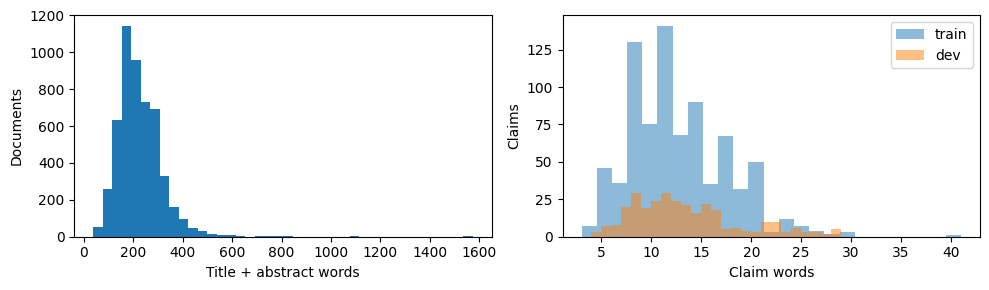

In [2]:
summary, documents, claims, rationales = study.eda()
display(summary)
display(documents[['words', 'sentences']].describe().round(2))
display(claims.groupby('split')['words'].describe().round(2))
display(rationales.groupby(['split', 'label'])['sentences'].agg(['count', 'mean', 'max']).round(2))
display(pd.Series(study.dataset.manifest).drop(['sha256', 'train_ids', 'validation_ids', 'dev_ids']))
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(documents['words'], bins=40)
axes[0].set(xlabel='Title + abstract words', ylabel='Documents')
for split in ['train', 'dev']:
    axes[1].hist(claims.loc[claims.split == split, 'words'], bins=25, alpha=.5, label=split)
axes[1].set(xlabel='Claim words', ylabel='Claims')
axes[1].legend(); plt.tight_layout(); plt.show()

In [3]:
# Real support and contradiction examples from training annotations.
examples = []
for label in ['SUPPORT', 'CONTRADICT']:
    for c in study.dataset.train:
        matches = [(doc, r) for doc, rs in c.get('evidence', {}).items() for r in rs if r['label'] == label]
        if matches:
            doc, rationale = matches[0]
            examples.append({'claim_id': c['id'], 'claim': c['claim'], 'label': label, 'doc_id': int(doc),
                             'original_indices': rationale['sentences'], 'evidence': ' '.join(
                                 study.dataset.corpus[int(doc)]['abstract'][i] for i in rationale['sentences'])})
            break
display(pd.DataFrame(examples))

,claim_id,claim,label,doc_id,original_indices,evidence
0,9,32% of liver transplantation programs required...,SUPPORT,44265107,[15],Policies requiring discontinuation of methadon...
1,2,1 in 5 million in UK have abnormal PrP positiv...,CONTRADICT,13734012,[4],"RESULTS Of the 32,441 appendix samples 16 were..."


## 4. Methodology and evaluation definitions

We form an internal validation split from original training claims using connected components that share
cited papers or identical normalized claim text. This keeps related claim variants together. The official dev
texts are used only to remove exact duplicated training copies; dev evidence labels never enter training,
negative mining, or tuning. The official train/dev split still shares corpus documents, as is normal for retrieval.

Recall@K is the macro mean fraction of a claim's gold documents retrieved. Hit@10 is the mean indicator that
at least one gold document appears in the first 10. MRR@10 uses the reciprocal rank of the first relevant document,
with zero for a miss. Retrieval excludes claims without evidence because their recall denominator is zero.
nDCG@10 has binary relevance. Evidence overlap is micro-averaged; best-rationale recall at a sentence budget
averages over annotated claim-document pairs, choosing the best covered alternative rationale.

Official SciFact abstract correctness requires the correct stance **and a complete gold rationale contained
in the first three predicted sentences**. Sentence correctness requires the whole rationale, not partial overlap.
The vendored evaluator is unmodified and tested against the official documentation's example. Claim accuracy/F1
are simplified project metrics using a documented aggregation rule; they are not official SciFact scores.

In [4]:
import subprocess
checked = subprocess.run([sys.executable, '-m', 'pytest', '-q'], capture_output=True, text=True, check=True)
print(checked.stdout)

............                                                             [100%]
12 passed in 3.43s



## 5. Experiment A: BM25

BM25Okapi uses lowercase regex word tokens with default $k_1=1.5$, $b=0.75$. We compare abstract only with
title + abstract. No stemming or domain-specific stopword rules are added. All neural comparisons use the
same claim IDs, corpus, gold documents and metric implementation. The following table is internal validation only.

In [5]:
display(study.bm25().round(4))

Completed bm25


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
hybrid_pretrained,96,0.7092,0.8663,0.8976,0.9418,0.9531,0.9583,0.8282,0.8460
hybrid_random,96,0.7405,0.8559,0.8872,0.9314,0.9479,0.9479,0.8410,0.8530
bm25_abstract,96,0.6354,0.7795,0.8403,0.8715,0.9002,0.8958,0.7398,0.7659
hybrid_hard,96,0.7405,0.8663,0.8872,0.9314,0.9531,0.9479,0.8425,0.8544
dense_random,96,0.6901,0.8429,0.8611,0.9323,0.9375,0.9375,0.7997,0.8276
bm25_title_abstract,96,0.6406,0.7891,0.8403,0.8715,0.9106,0.8958,0.7470,0.7703
dense_hard,96,0.6832,0.8429,0.8854,0.9375,0.9375,0.9375,0.7988,0.8274
dense_pretrained,96,0.6484,0.8429,0.8854,0.9271,0.9375,0.9271,0.7793,0.8120
specter2,96,0.7248,0.8533,0.8932,0.9323,0.9740,0.9375,0.8190,0.8431


## 6. Experiment B: pretrained dense retrieval

all-MiniLM-L6-v2 produces mean-pooled, L2-normalized vectors with cosine search in memory. Corpus embeddings
are cached with corpus text and truncation fingerprints. We keep the model's 256-token document limit in full
mode and use batched inference. Dense query scores are meaningful only within the same model/configuration.

SPECTER2 uses its document proximity adapter and its distinct ad-hoc query adapter, CLS pooling and 512 tokens,
following the official model cards. Documents concatenate title, tokenizer separator, and abstract. It is
scheduled after the core stages so an optional dependency/model failure cannot block the core study. Its full
corpus result, or an explicit failure record, appears in the final retrieval table.

In [6]:
display(study.pretrained().round(4))

Completed pretrained_dense


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
hybrid_pretrained,96,0.7092,0.8663,0.8976,0.9418,0.9531,0.9583,0.8282,0.8460
hybrid_random,96,0.7405,0.8559,0.8872,0.9314,0.9479,0.9479,0.8410,0.8530
bm25_abstract,96,0.6354,0.7795,0.8403,0.8715,0.9002,0.8958,0.7398,0.7659
hybrid_hard,96,0.7405,0.8663,0.8872,0.9314,0.9531,0.9479,0.8425,0.8544
dense_random,96,0.6901,0.8429,0.8611,0.9323,0.9375,0.9375,0.7997,0.8276
bm25_title_abstract,96,0.6406,0.7891,0.8403,0.8715,0.9106,0.8958,0.7470,0.7703
dense_hard,96,0.6832,0.8429,0.8854,0.9375,0.9375,0.9375,0.7988,0.8274
dense_pretrained,96,0.6484,0.8429,0.8854,0.9271,0.9375,0.9271,0.7793,0.8120
specter2,96,0.7248,0.8533,0.8932,0.9323,0.9740,0.9375,0.8190,0.8431


## 7. Experiment C1: contrastive training with random negatives

Each positive is an annotated evidence abstract, regardless of SUPPORT/CONTRADICT. Negatives are sampled from
the remaining corpus. We exclude all known training-family evidence papers and cited papers. These exclusions
do not establish that every remaining paper is a true negative: SciFact annotations are incomplete.

The loss is multi-positive InfoNCE over explicit and in-batch document candidates. Other known positives are
positive targets; protected family documents are masked rather than used as false negatives. Both C1 and C2 start
from the same pretrained checkpoint and use identical seed, positive examples, batch size, schedule and epoch
budget. AdamW, linear warmup/decay, norm-1 gradient clipping, validation checkpointing and patience-based early
stopping are used. Checkpoints maximize validation Recall@10, breaking ties with MRR@10.
The executed GPU loops use dynamic AMP loss scaling and a batch-iteration learning-rate schedule:
overflowing batches can skip optimizer updates while the schedule advances. A repetition emitted a
scheduler-order warning; this numerical limitation is retained in the discussion.

In [7]:
display(study.contrastive('random').round(4))
from scifact_project.data import read_jsonl
training_pairs = pd.DataFrame(read_jsonl(config.out / 'tables/retriever_random_pairs.jsonl'))
display(training_pairs[['claim_id', 'claim', 'positive', 'negative', 'negative_mode']].head())

Completed dense_random


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
hybrid_pretrained,96,0.7092,0.8663,0.8976,0.9418,0.9531,0.9583,0.8282,0.8460
hybrid_random,96,0.7405,0.8559,0.8872,0.9314,0.9479,0.9479,0.8410,0.8530
bm25_abstract,96,0.6354,0.7795,0.8403,0.8715,0.9002,0.8958,0.7398,0.7659
hybrid_hard,96,0.7405,0.8663,0.8872,0.9314,0.9531,0.9479,0.8425,0.8544
dense_random,96,0.6901,0.8429,0.8611,0.9323,0.9375,0.9375,0.7997,0.8276
bm25_title_abstract,96,0.6406,0.7891,0.8403,0.8715,0.9106,0.8958,0.7470,0.7703
dense_hard,96,0.6832,0.8429,0.8854,0.9375,0.9375,0.9375,0.7988,0.8274
dense_pretrained,96,0.6484,0.8429,0.8854,0.9271,0.9375,0.9271,0.7793,0.8120
specter2,96,0.7248,0.8533,0.8932,0.9323,0.9740,0.9375,0.8190,0.8431


,claim_id,claim,positive,negative,negative_mode
0,2,1 in 5 million in UK have abnormal PrP positiv...,13734012,2494748,random
1,9,32% of liver transplantation programs required...,44265107,27731651,random
2,12,40mg/day dosage of folic acid and 2mg/day dosa...,33409100,22995579,random
3,22,76-85% of people with severe mental disorder r...,6490571,13903052,random
4,30,A breast cancer patient's capacity to metaboli...,24341590,13777138,random


## 8. Experiment C2: BM25 hard negatives

We sample from the first 20 permissible candidates among BM25's top 100. Positive/family/citation exclusions
are identical to C1. Mining uses training claims only and does not inspect dev annotations. Saved pair manifests
make the exact positive and negative choices auditable. Hard negatives may still be unannotated relevant papers;
we discuss this source of noise rather than interpreting sampled negatives as verified scientific refutations.

In [8]:
display(study.contrastive('hard').round(4))

Completed dense_hard


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
hybrid_pretrained,96,0.7092,0.8663,0.8976,0.9418,0.9531,0.9583,0.8282,0.8460
hybrid_random,96,0.7405,0.8559,0.8872,0.9314,0.9479,0.9479,0.8410,0.8530
bm25_abstract,96,0.6354,0.7795,0.8403,0.8715,0.9002,0.8958,0.7398,0.7659
hybrid_hard,96,0.7405,0.8663,0.8872,0.9314,0.9531,0.9479,0.8425,0.8544
dense_random,96,0.6901,0.8429,0.8611,0.9323,0.9375,0.9375,0.7997,0.8276
bm25_title_abstract,96,0.6406,0.7891,0.8403,0.8715,0.9106,0.8958,0.7470,0.7703
dense_hard,96,0.6832,0.8429,0.8854,0.9375,0.9375,0.9375,0.7988,0.8274
dense_pretrained,96,0.6484,0.8429,0.8854,0.9271,0.9375,0.9271,0.7793,0.8120
specter2,96,0.7248,0.8533,0.8932,0.9323,0.9740,0.9375,0.8190,0.8431


## 9. Experiment D: hybrid rank fusion

Reciprocal Rank Fusion combines rank positions rather than incompatible raw score scales:
$s(d)=w/(c+r_{BM25}(d))+(1-w)/(c+r_{dense}(d))$, omitting a term when a document is absent.
For each pretrained/random/hard dense retriever we tune c in {10, 60} and w in {0.25, 0.5, 0.75} on
internal validation only, with input depth 50. A trained dense variant is selected for the deployed hybrid
using the same validation criterion. Dev comparisons do not feed back into this choice.

In [9]:
display(study.hybrid().round(4)); display(pd.Series(study.selection))

Completed hybrid


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
hybrid_pretrained,96,0.7092,0.8663,0.8976,0.9418,0.9531,0.9583,0.8282,0.8460
hybrid_random,96,0.7405,0.8559,0.8872,0.9314,0.9479,0.9479,0.8410,0.8530
bm25_abstract,96,0.6354,0.7795,0.8403,0.8715,0.9002,0.8958,0.7398,0.7659
hybrid_hard,96,0.7405,0.8663,0.8872,0.9314,0.9531,0.9479,0.8425,0.8544
dense_random,96,0.6901,0.8429,0.8611,0.9323,0.9375,0.9375,0.7997,0.8276
bm25_title_abstract,96,0.6406,0.7891,0.8403,0.8715,0.9106,0.8958,0.7470,0.7703
dense_hard,96,0.6832,0.8429,0.8854,0.9375,0.9375,0.9375,0.7988,0.8274
dense_pretrained,96,0.6484,0.8429,0.8854,0.9271,0.9375,0.9271,0.7793,0.8120
specter2,96,0.7248,0.8533,0.8932,0.9323,0.9740,0.9375,0.8190,0.8431


dense_mode                                                                      hard
hybrid_name                                                              hybrid_hard
rrf_constant                                                                      10
rrf_weight                                                                       0.5
dense_embeddings_path              outputs/full_gpu_seed42/cache/corpus_hard_0a00...
sentence_threshold                                                              0.85
stance_threshold                                                                 0.5
document_threshold                                                               0.0
validation_official_abstract_f1                                             0.334842
validation_claim_macro_f1                                                   0.526806
tuning_split                                                internal_validation_only
dtype: object

## 10. Experiment E: pretrained cross-encoder reranking

ms-marco-MiniLM-L6-v2 scores claim–document pairs from the selected hybrid's top 20 candidates. This is a
general-domain pretrained relevance model, not a scientific stance classifier. Candidate-set equality is
asserted before/after reranking. We report its per-query scoring cost separately from initial retrieval and
index construction. Its top-20 recall cannot exceed the fixed candidate set's recall.

In [10]:
display(study.reranking().round(4))

Completed reranking


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
hybrid_pretrained,96,0.7092,0.8663,0.8976,0.9418,0.9531,0.9583,0.8282,0.8460
hybrid_random,96,0.7405,0.8559,0.8872,0.9314,0.9479,0.9479,0.8410,0.8530
bm25_abstract,96,0.6354,0.7795,0.8403,0.8715,0.9002,0.8958,0.7398,0.7659
hybrid_hard,96,0.7405,0.8663,0.8872,0.9314,0.9531,0.9479,0.8425,0.8544
dense_random,96,0.6901,0.8429,0.8611,0.9323,0.9375,0.9375,0.7997,0.8276
bm25_title_abstract,96,0.6406,0.7891,0.8403,0.8715,0.9106,0.8958,0.7470,0.7703
dense_hard,96,0.6832,0.8429,0.8854,0.9375,0.9375,0.9375,0.7988,0.8274
dense_pretrained,96,0.6484,0.8429,0.8854,0.9271,0.9375,0.9271,0.7793,0.8120
specter2,96,0.7248,0.8533,0.8932,0.9323,0.9740,0.9375,0.8190,0.8431


## 11. Experiment F: supervised evidence extraction

The baseline ranks individual abstract sentences by pretrained embedding cosine similarity to the claim.
The supervised selector trains on claim–sentence pairs with binary labels from the union of alternative gold
rationales. It keeps all positives and samples up to three negatives per positive. Non-rationale sentences and
cited-but-unannotated abstracts provide negatives; the latter are weak labels, recorded by source.

The CPU profile fine-tunes the six-layer MiniLM encoder to complete the study within available resources.
The GPU profile uses SciBERT. Weighted cross entropy handles class imbalance; validation macro F1 selects epochs.
Sentence and pipeline thresholds are subsequently tuned using **retrieved validation documents**, with a maximum
of three sentences per document. We evaluate gold-document and retrieved-document settings and both overlap
and official complete-rationale metrics. Independent classification cannot fully model jointly necessary evidence.

## 12. Experiment G: stance verification

Each complete annotated rationale creates a claim–evidence example labeled SUPPORT or CONTRADICT; alternatives
remain separate. No arbitrary unannotated abstract is assigned an NEI stance. The first simple model is TF-IDF
plus balanced logistic regression. The transformer is independently fine-tuned with the same weighted loss,
scheduling and checkpoint practices as the selector. NEI is handled only by pipeline relevance/confidence filters.

In [11]:
display(study.supervised())

{'accuracy': 0.7027027027027027,
 'macro_f1': 0.6935333273094184,
 'per_class': {'CONTRADICT': {'precision': 0.5632183908045977,
   'recall': 0.7424242424242424,
   'f1-score': 0.6405228758169934,
   'support': 66.0},
  'SUPPORT': {'precision': 0.826530612244898,
   'recall': 0.680672268907563,
   'f1-score': 0.7465437788018433,
   'support': 119.0},
  'accuracy': 0.7027027027027027,
  'macro avg': {'precision': 0.6948745015247478,
   'recall': 0.7115482556659027,
   'f1-score': 0.6935333273094184,
   'support': 185.0},
  'weighted avg': {'precision': 0.7325921981094395,
   'recall': 0.7027027027027027,
   'f1-score': 0.7087201053045455,
   'support': 185.0}},
 'confusion_matrix': [[49, 17], [38, 81]],
 'label_order': ['CONTRADICT', 'SUPPORT'],
 'examples': 185,
 'setting': 'Every complete gold rationale separately',
 'split': 'internal_validation',
 'checkpoint': 'outputs/full_gpu_seed42/checkpoints/stance'}

## 13. End-to-end integration and validation-only acceptance tuning

The deployed pipeline verifies the reranked top five documents. It selects up to three sentences above a
validation-tuned selector threshold and predicts binary stance on those sentences in original abstract order.
Stance confidence and relevance-logit thresholds are tuned on internal validation official rationalized F1.
When accepted documents disagree, the claim verdict is the label of the document with largest selector score
times stance probability; ties choose the smallest document ID. This is our aggregation policy, not an official rule.
An empty accepted set yields NOT ENOUGH INFO. Scores are uncalibrated model outputs, not truth probabilities.

In [12]:
end_to_end = study.final_evaluation()
display(pd.Series(study.selection))
print('All configurations are frozen. Final comparisons below use official dev; test remains unlabeled.')

dense_mode                                                                      hard
hybrid_name                                                              hybrid_hard
rrf_constant                                                                      10
rrf_weight                                                                       0.5
dense_embeddings_path              outputs/full_gpu_seed42/cache/corpus_hard_0a00...
sentence_threshold                                                              0.85
stance_threshold                                                                 0.5
document_threshold                                                               0.0
validation_official_abstract_f1                                             0.334842
validation_claim_macro_f1                                                   0.526806
tuning_split                                                internal_validation_only
dtype: object

All configurations are frozen. Final comparisons below use official dev; test remains unlabeled.


## 14. Oracle and controlled ablation settings

We compare predicted documents/evidence/stance, gold documents with predicted evidence/stance, and gold
documents with a complete gold rationale and predicted stance. Oracle evidence uses the shortest complete
alternative per document, deterministically. Oracle settings are diagnostics and never enter `predict`.
Both gold-document settings retain the same stance-confidence threshold; known gold relevance bypasses
the document-relevance filter in both. Thus the second oracle changes evidence, not acceptance policy.

Two retrieval ablations reuse the trained selector, stance model and sentence/stance thresholds with BM25
or the hybrid before reranking. The hybrid ordering ablation uses the exact same cross-encoder document scores
and acceptance thresholds, so only the ordering changes. BM25 omits that relevance-logit filter; its comparison
has this additional difference. Official scores retain document-level
predictions; a separate table shows simplified aggregate claim metrics.

## 15. Supplementary SPECTER2 experiment

The adapters/Transformers versions are pinned together because the initially installed Transformers 5 release
was not the adapter-compatible environment used here. `scripts/probe_models.py` checks both adapter forward
passes. This cell evaluates the entire current-mode corpus when enabled and records any unavoidable failure.
SPECTER2 is supplementary and never changes the already selected pipeline after dev evaluation.

In [13]:
study.specter2()
display(study.status.get('specter2'))
study.refresh_fusion_costs()
retrieval_table = study.save_retrieval_tables()
from scifact_project.report import generate_report
retrieval, evidence, stance, ablations = generate_report(study)

{'status': 'completed',
 'details': {'adapter_device_fix': 'Both adapters loaded before complete-model device transfer'}}

## 16. Final retrieval comparisons (official dev)

,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10,query_seconds,cost_scope,milliseconds_per_query
experiment,,,,,,,,,,,,
bm25_abstract,188,0.6698,0.8236,0.8635,0.8998,0.9224,0.9149,0.7678,0.7960,5.9072,Batched query inference and search; indexing/m...,19.6908
bm25_title_abstract,188,0.6857,0.8236,0.8848,0.9158,0.9437,0.9309,0.7822,0.8110,5.9584,Batched query inference and search; indexing/m...,19.8613
dense_pretrained,188,0.6126,0.8069,0.8685,0.9117,0.9516,0.9202,0.7314,0.7743,0.2746,Batched query inference and search; indexing/m...,0.9152
specter2,188,0.6800,0.7859,0.8630,0.9180,0.9725,0.9309,0.7663,0.8005,1.4301,Batched query inference and search; indexing/m...,4.7670
dense_random,188,0.6374,0.8238,0.8659,0.9266,0.9622,0.9309,0.7519,0.7949,0.2715,Batched query inference and search; indexing/m...,0.9050
dense_hard,188,0.6454,0.8122,0.8889,0.9319,0.9676,0.9362,0.7576,0.8001,0.2847,Batched query inference and search; indexing/m...,0.9491
hybrid_pretrained,188,0.6791,0.8874,0.9065,0.9545,0.9718,0.9681,0.7999,0.8346,6.2426,Measured lexical query + dense query + fusion;...,20.8087
hybrid_random,188,0.6933,0.8657,0.9065,0.9519,0.9745,0.9628,0.8030,0.8375,6.2391,Measured lexical query + dense query + fusion;...,20.7971
hybrid_hard,188,0.7012,0.8887,0.9082,0.9505,0.9745,0.9628,0.8086,0.8411,6.2524,Measured lexical query + dense query + fusion;...,20.8412


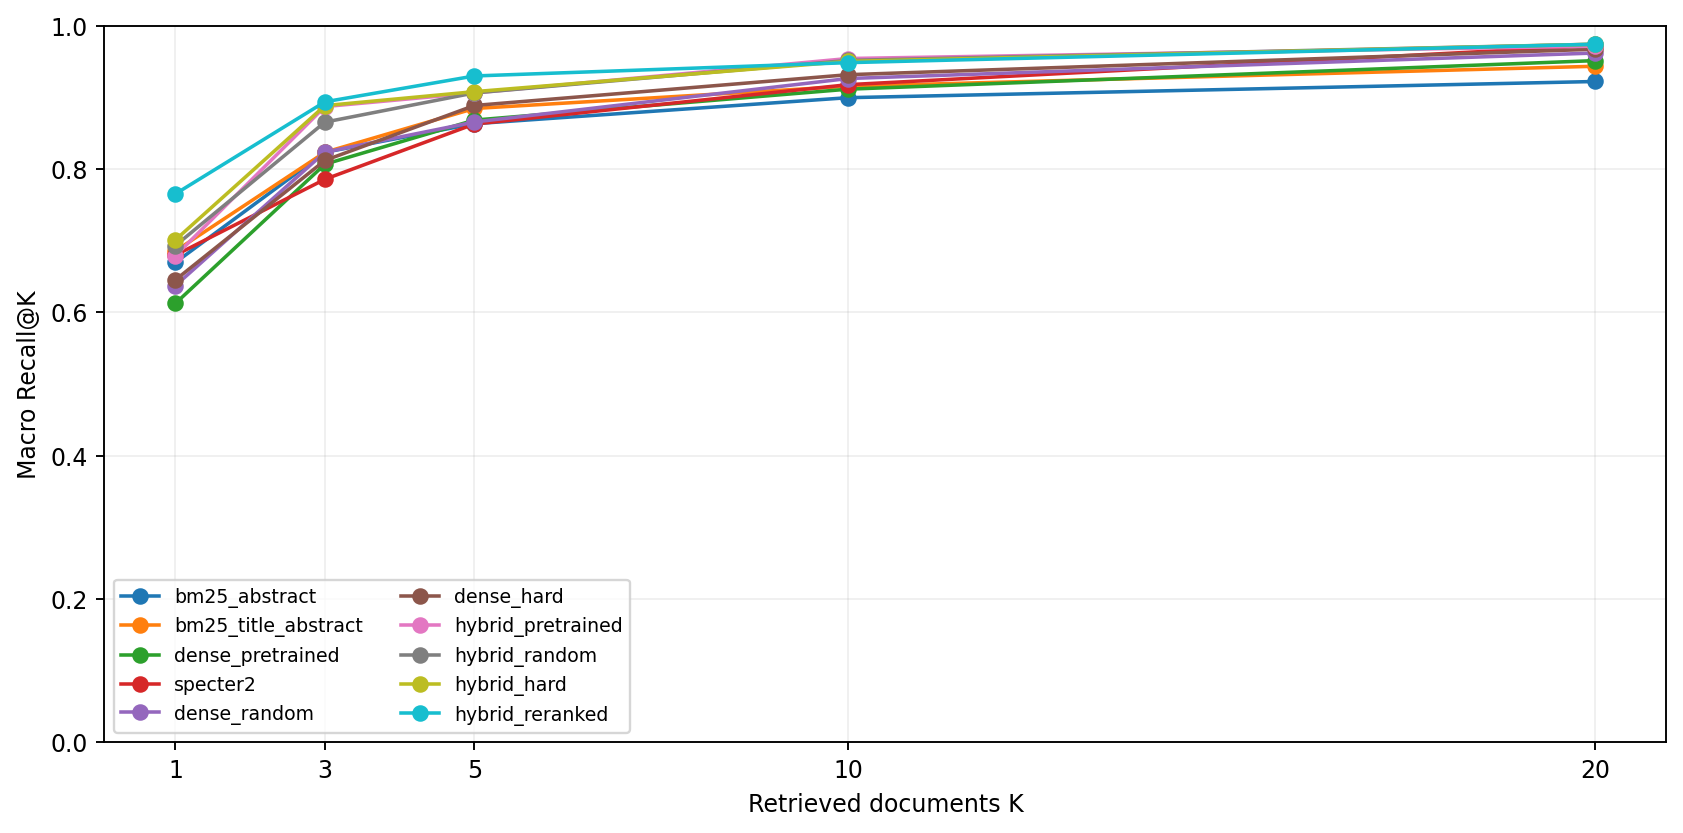

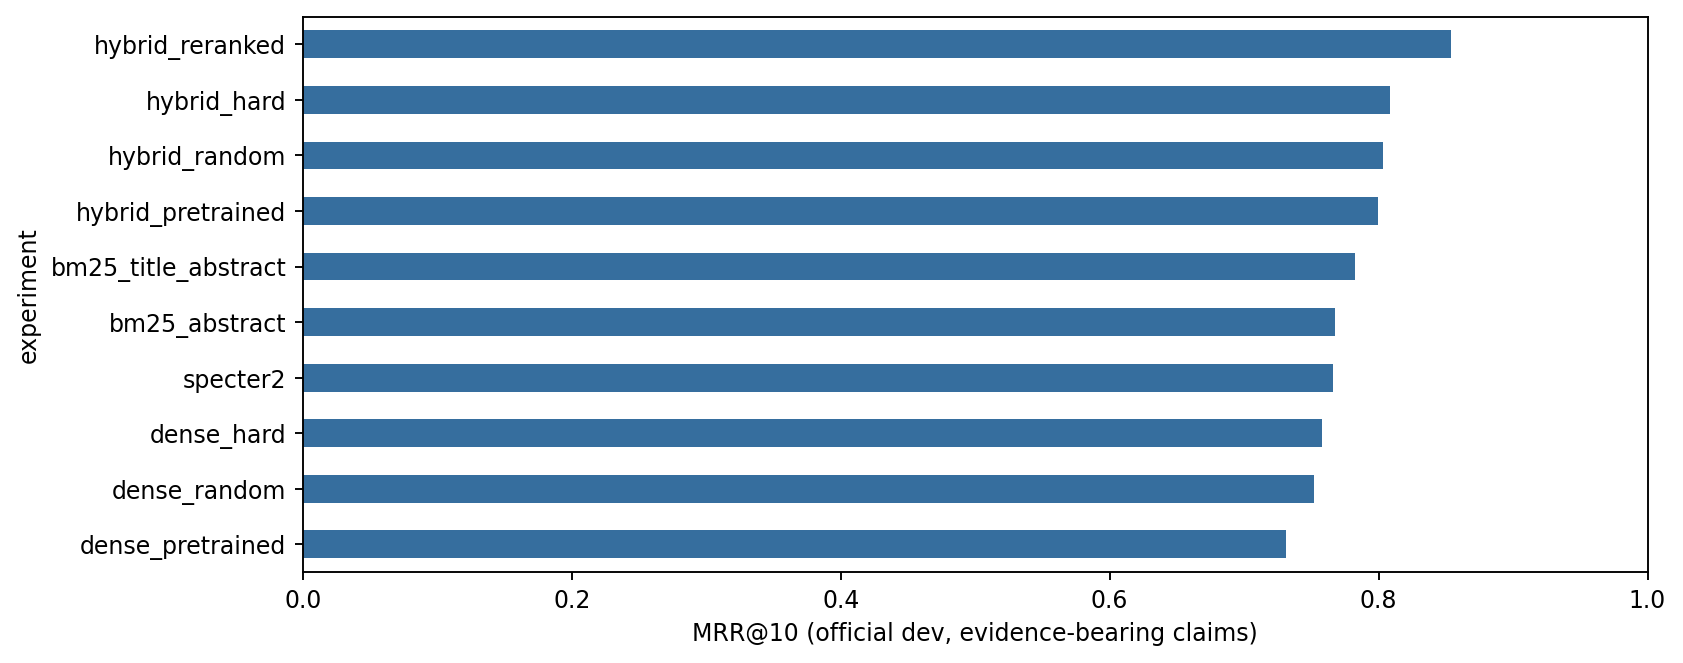

In [14]:
display(retrieval.loc[retrieval.split == 'dev'].drop(columns=['split', 'seed']).set_index('experiment').round(4))
display(Image(filename=str(config.out / 'figures/retrieval_recall.png')))
display(Image(filename=str(config.out / 'figures/retrieval_mrr.png')))

## 17. Evidence, stance, and end-to-end comparisons

,model,setting,threshold,precision,recall,f1,best_rationale_recall@budget,fixed_budget_best_rationale_recall,official_selection_f1
0,similarity,retrieved_documents,0.65,0.1805,0.3443,0.2368,0.4801,0.7273,0.2162
1,similarity,gold_documents,0.65,0.4346,0.3634,0.3958,0.5112,0.8038,0.3601
2,supervised,retrieved_documents,0.85,0.3706,0.5437,0.4408,0.6539,0.8461,0.4142
3,supervised,gold_documents,0.85,0.7500,0.5820,0.6554,0.7041,0.9418,0.6154


,model_setting,accuracy,macro_f1,examples,coverage
0,TF-IDF + logistic regression (gold rationale),0.4201,0.3875,338,1.0000
1,Trained transformer (gold rationale),0.6154,0.5874,338,1.0000
2,"Trained transformer (predicted evidence, condi...",0.6074,0.5750,163,0.7799


,setting,claim_accuracy,claim_macro_f1,official_abstract_label_only_f1,official_abstract_rationalized_f1,official_sentence_selection_f1,official_sentence_label_f1
0,predicted_all,0.5900,0.5531,0.3651,0.3237,0.4347,0.2466
1,gold_documents,0.6800,0.6286,0.5323,0.4677,0.6154,0.3446
2,gold_documents_gold_evidence,0.7900,0.7483,0.6459,0.6459,0.7614,0.4941
3,bm25_predicted,0.6100,0.5785,0.3468,0.3083,0.4079,0.2410
4,hybrid_without_reranking,0.5967,0.5577,0.3712,0.3319,0.4436,0.2484


,sentence_selection,sentence_label,abstract_label_only,abstract_rationalized
precision,0.3929,0.2230,0.3223,0.2857
recall,0.4863,0.2760,0.4211,0.3732
f1,0.4347,0.2466,0.3651,0.3237


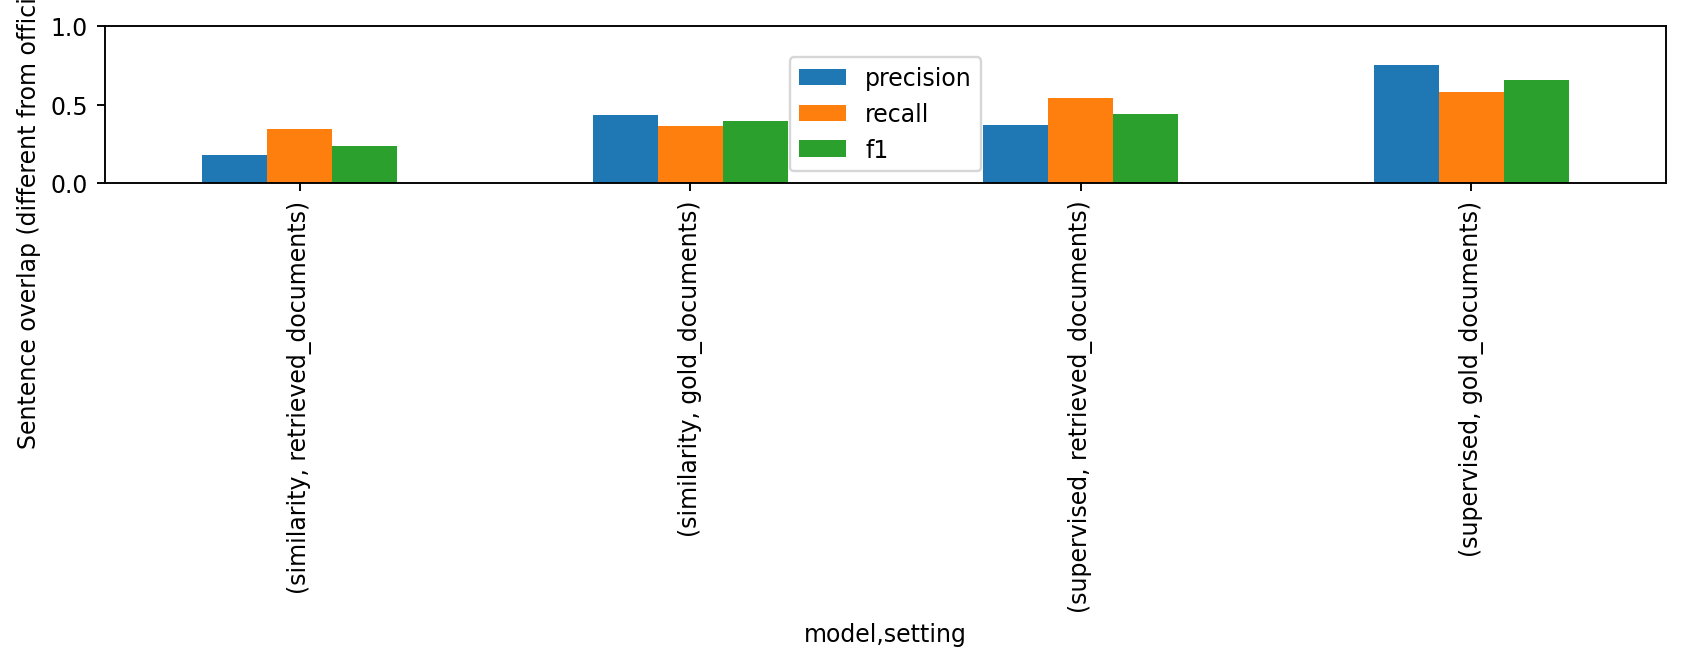

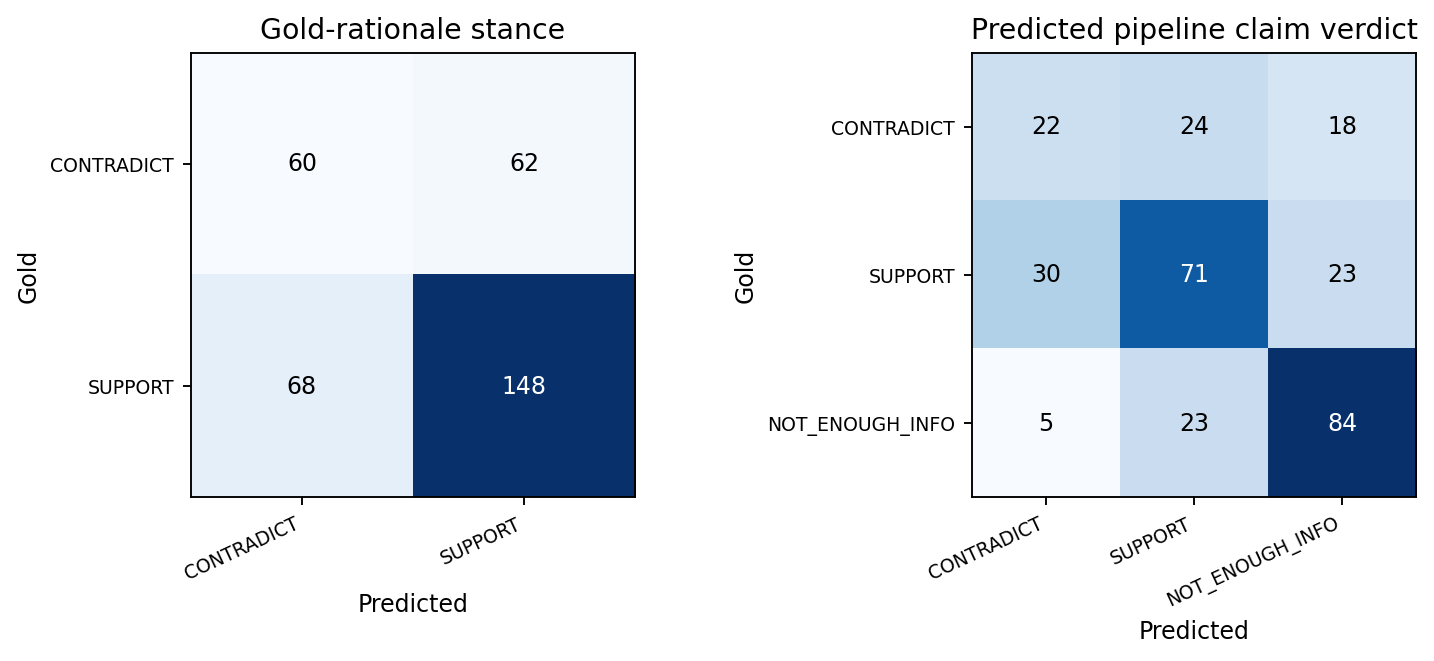

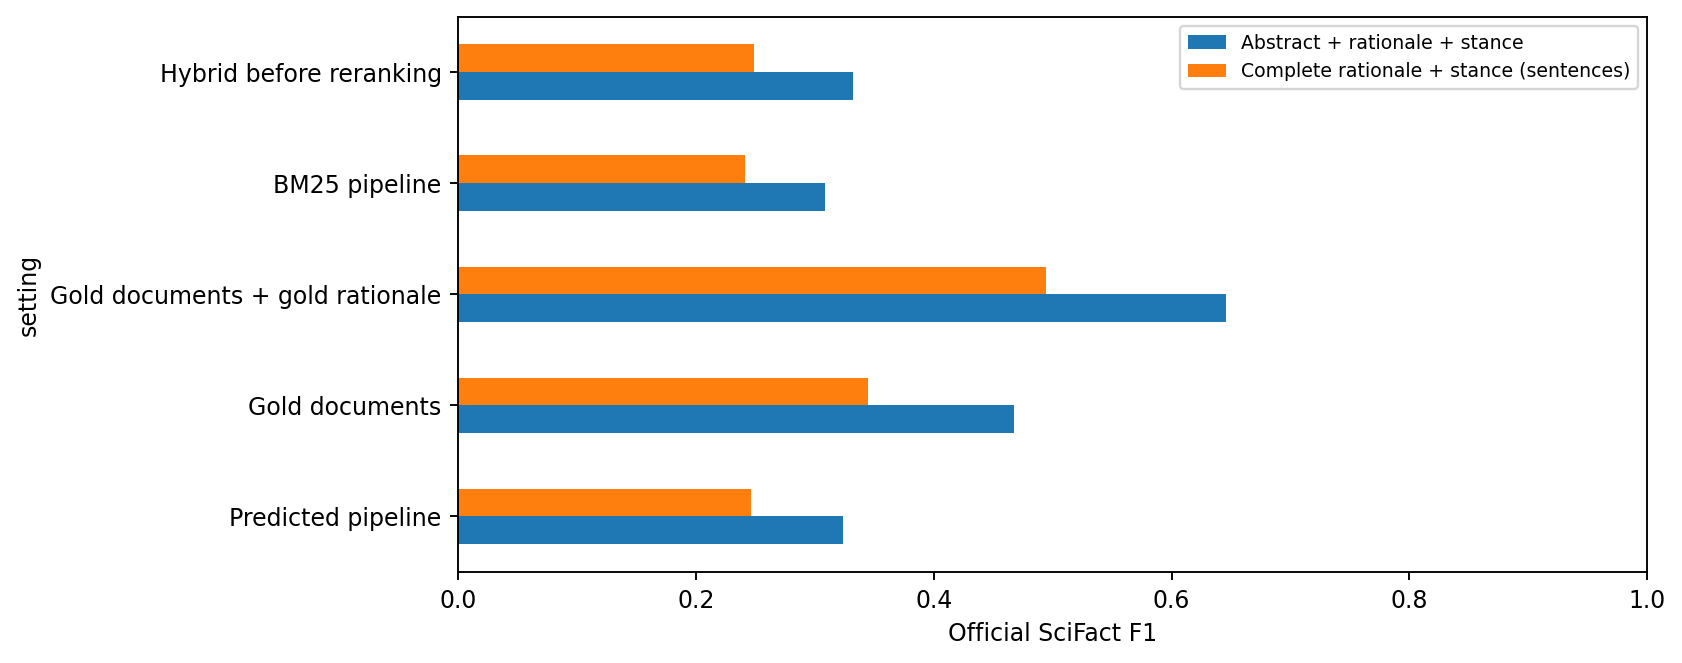

,precision,recall,f1-score,support
CONTRADICT,0.4688,0.4918,0.4800,122.0
SUPPORT,0.7048,0.6852,0.6948,216.0
macro avg,0.5868,0.5885,0.5874,338.0
weighted avg,0.6196,0.6154,0.6173,338.0


In [15]:
display(evidence.round(4))
display(stance.round(4))
display(ablations.round(4))
display(pd.DataFrame(end_to_end['predicted_all']['official']).round(4))
for name in ['evidence_selection', 'confusion_matrices', 'end_to_end_ablations']:
    display(Image(filename=str(config.out / 'figures' / f'{name}.png')))
gold_stance = json.loads((config.out / 'metrics/stance_gold.json').read_text())
per_class = {label: values for label, values in gold_stance['per_class'].items() if isinstance(values, dict)}
display(pd.DataFrame.from_dict(per_class, orient='index').round(4))

## 18. Data distributions, learning curves, and sampling uncertainty

Pair classifiers use class-weighted training cross entropy; plotted validation cross entropy is unweighted.
Their loss levels therefore measure different weightings. Retrieval curves show training InfoNCE loss and
held-out ranking quality, since validation Recall@10 is the checkpoint-selection criterion.

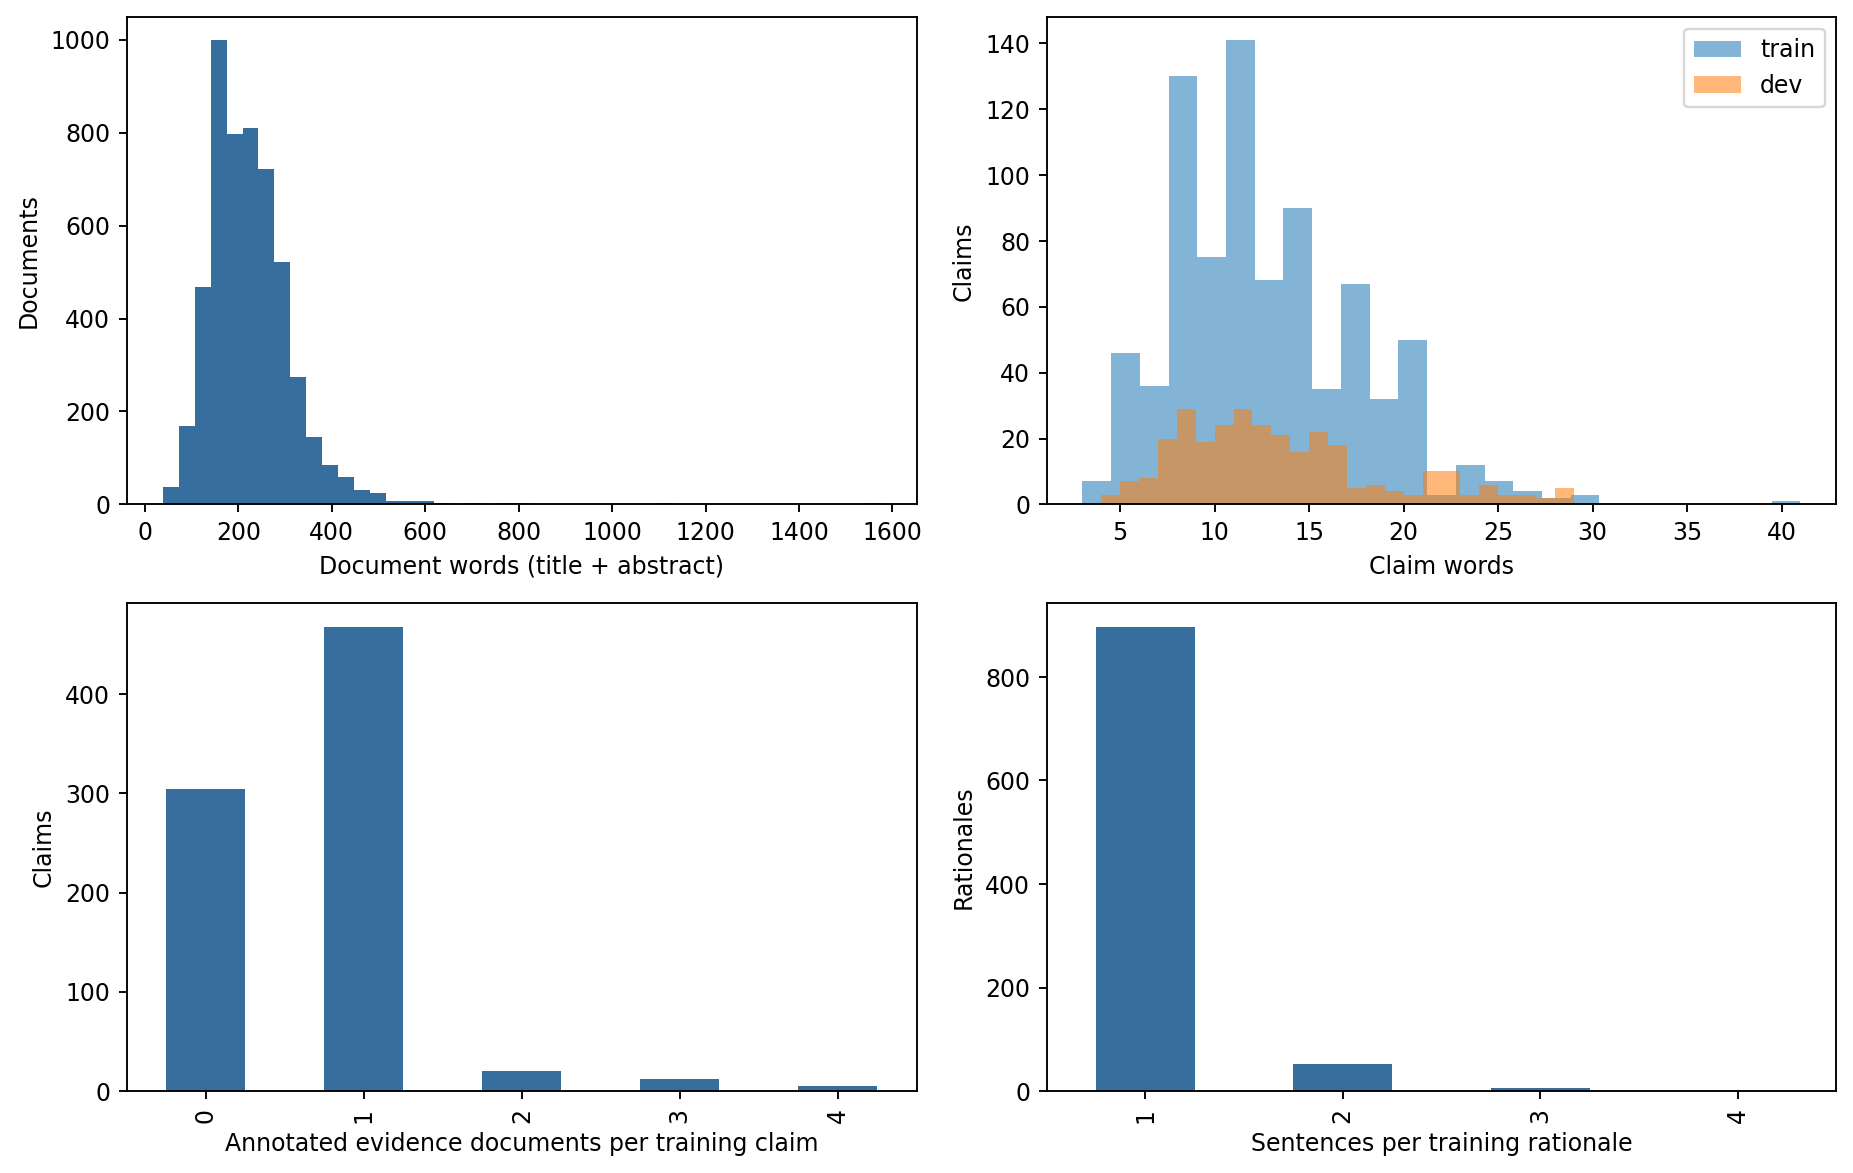

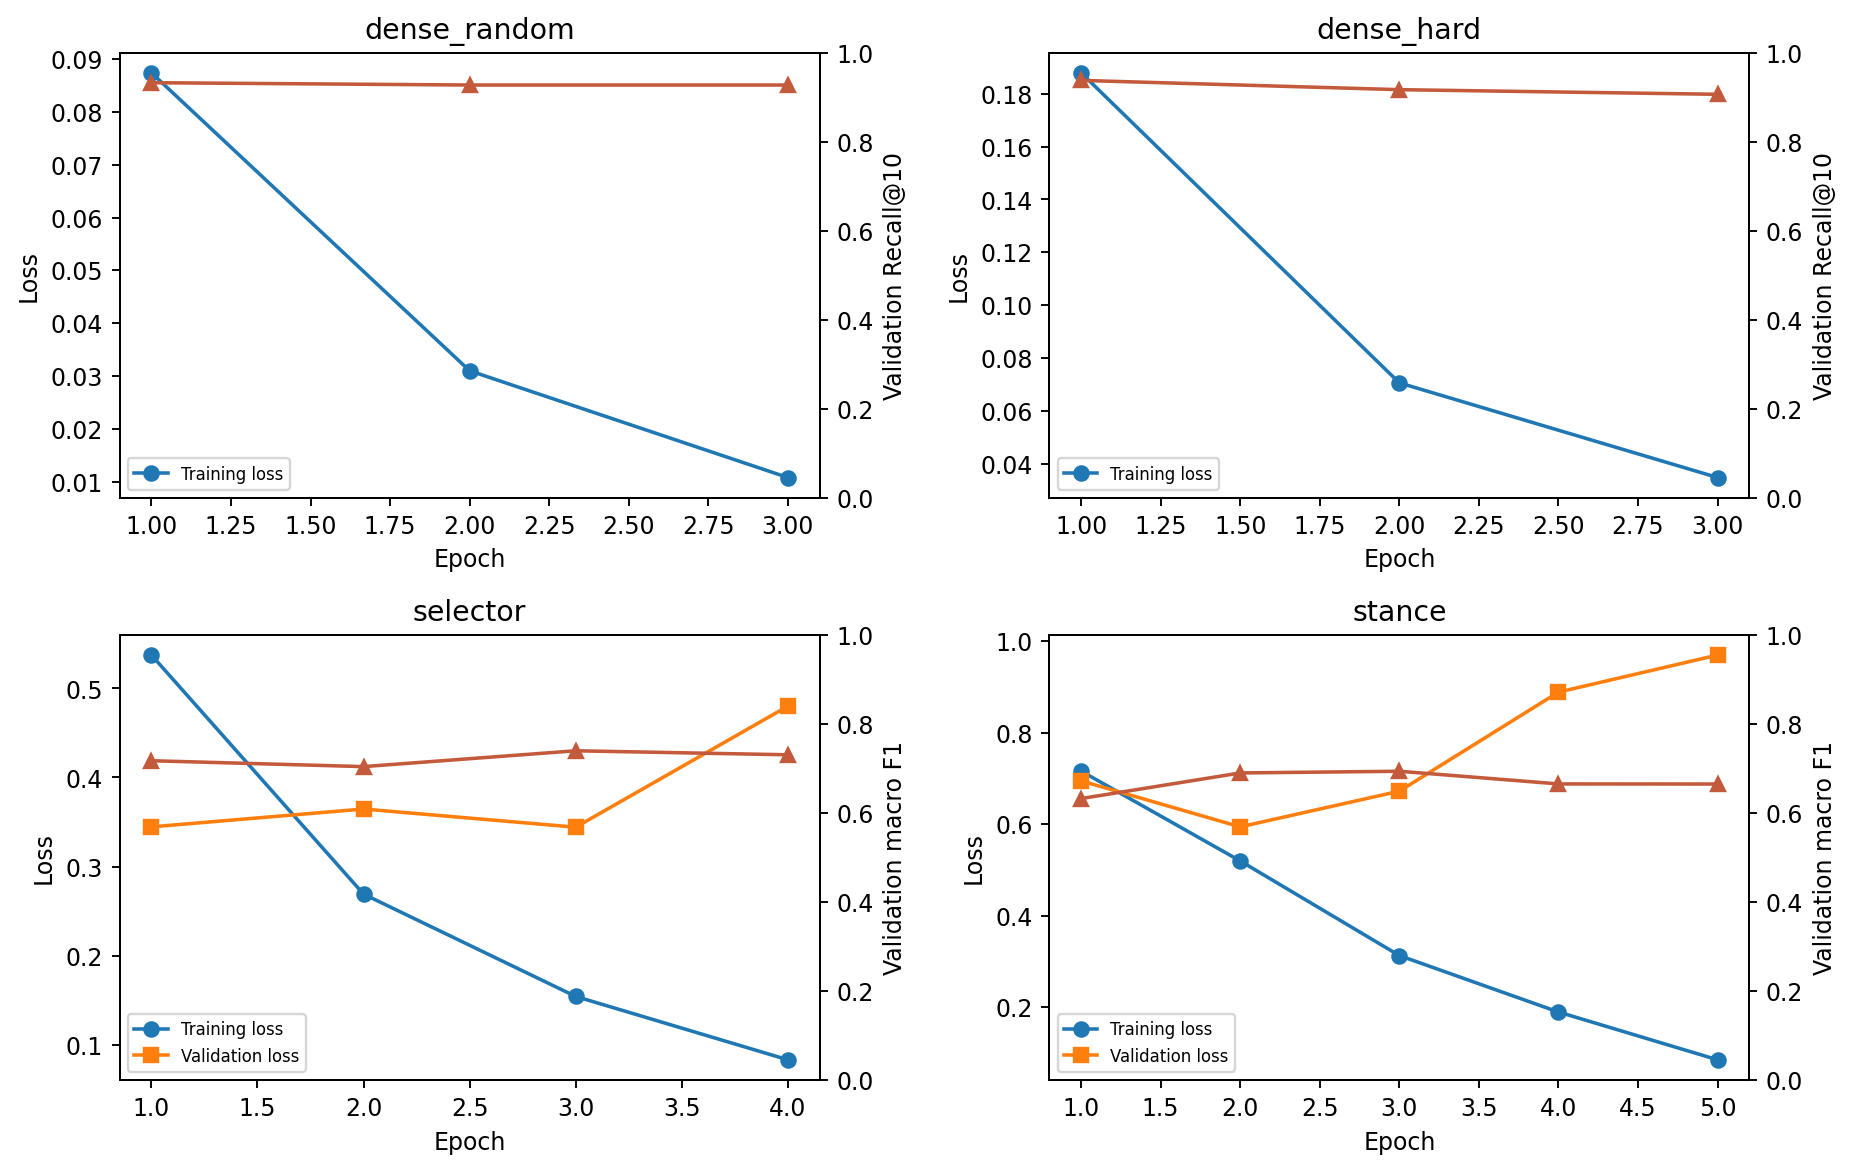

,model,checkpoint,base_model,seed,device,epochs_run,selected_epoch,training_seconds,effective_batch_size
0,dense_random,outputs/full_gpu_seed42/checkpoints/dense_random,sentence-transformers/all-MiniLM-L6-v2,42,cuda,3,1,222.85,16
1,dense_hard,outputs/full_gpu_seed42/checkpoints/dense_hard,sentence-transformers/all-MiniLM-L6-v2,42,cuda,3,1,175.71,16
2,selector,outputs/full_gpu_seed42/checkpoints/selector,allenai/scibert_scivocab_uncased,42,cuda,4,3,1559.70,16
3,stance,outputs/full_gpu_seed42/checkpoints/stance,allenai/scibert_scivocab_uncased,42,cuda,5,3,534.46,16


,left,right,metric,mean_difference,percentile_95_ci,resamples,clusters,interpretation
0,bm25_title_abstract,hybrid_reranked,MRR@10,0.071992,"[0.028856349455454913, 0.114913135020717]",2000,164,Citation-family cluster sampling uncertainty; ...
1,dense_random,dense_hard,MRR@10,0.005705,"[-0.021908936450884375, 0.03003792769475214]",2000,164,Citation-family cluster sampling uncertainty; ...


,experiment,seeds,runs,Recall@1,Recall@5,Recall@10,MRR@10
0,dense_hard,"42,43,44",3,0.6628 ± 0.0151,0.8840 ± 0.0043,0.9372 ± 0.0070,0.7676 ± 0.0089
1,dense_random,"42,43,44",3,0.6578 ± 0.0200,0.8673 ± 0.0059,0.9346 ± 0.0096,0.7635 ± 0.0131


In [16]:
for name in ['data_distributions', 'training_curves']:
    display(Image(filename=str(config.out / 'figures' / f'{name}.png')))
display(pd.read_csv(config.out / 'tables/training_summary.csv').round(2))
display(pd.DataFrame(json.loads((config.out / 'metrics/paired_bootstrap.json').read_text())))
seed_summary = config.out / 'tables/retriever_seed_summary.csv'
if seed_summary.exists():
    seeded = pd.read_csv(seed_summary)
    formatted = seeded[['experiment', 'seeds', 'runs']].copy()
    for metric in ['Recall@1', 'Recall@5', 'Recall@10', 'MRR@10']:
        formatted[metric] = [f'{mean:.4f} ± {std:.4f}' for mean, std in
                             zip(seeded[f'{metric}_mean'], seeded[f'{metric}_std'])]
    display(formatted)

## 19. Measured discussion, five concrete errors, and conclusions

This report is generated from actual saved metrics. Differences are in percentage points, while tables use
fractions. Failure categories are determined from retrieval, selection, and stance outputs; they do not imply
unobserved linguistic explanations. The selected main checkpoint and downstream pipeline use one seed;
repeated-retriever results appear above when available. Bootstrap intervals resample citation families
to account for related claims and cannot replace repeated training seeds.

In [17]:
display(Markdown((config.out / 'analysis.md').read_text()))

## Measured findings

This is a **full-data GPU study** with main-pipeline training seed 42; retrieval seed repetitions, if completed, are described below.
Retrieval is evaluated on 188 evidence-bearing official dev claims;
end-to-end metrics include all 300 dev claims. No test metrics are reported.

The highest dev MRR@10 is **hybrid_reranked**, 0.8542,
+7.20 percentage points relative to title+abstract BM25.
The highest Recall@10 is **hybrid_pretrained**, 0.9545.
These are descriptive comparisons across prespecified experiments, not dev-driven model selection.
Deployment uses hybrid_hard followed by reranking, chosen with internal validation labels only.

Adding titles to BM25 changes MRR@10 by +1.44 points and
Recall@10 by +1.60 points.

Pretrained MiniLM versus BM25 changes MRR@10 by -5.08 points
and Recall@10 by -0.41 points.
SPECTER2 changes MRR@10 versus BM25 by -1.59 points and Recall@10 by +0.22 points.

Random-negative fine-tuning versus pretrained MiniLM changes MRR@10 by
+2.05 points and Recall@10 by
+1.49 points.
Hard negatives versus random negatives change MRR@10 by +0.57 points
and Recall@10 by +0.53 points.
The hybrid_hard fusion changes MRR@10 versus its trained dense input by
+5.10 points
and versus BM25 by +2.64 points.
Reranking the exact same 20 hybrid candidates changes Recall@1 by
+6.43 points and MRR@10 by
+4.56 points. Its candidate Recall@20 cannot improve when the pool is fixed.
Its measured cross-encoder scoring adds 174.23 ms per claim to the hybrid's 20.84 ms,
averaged over batched queries; indexing and model loading are excluded. This throughput measure is not single-query latency.
The controlled end-to-end reranking-order comparison changes official rationalized abstract F1 by
-0.82 points, with the same cross-encoder acceptance scores and thresholds in both settings.

For retrieved documents, supervised selection changes official sentence-selection F1 versus the
embedding-similarity baseline by +19.80 points. This comparison uses each selector's
independently validation-tuned threshold and the same maximum sentence budget.

The trained gold-rationale stance model has accuracy 0.6154 and macro F1
0.5874; the TF-IDF baseline has macro F1 0.3875.
Gold-rationale examples include every alternative rationale separately, so this table has a different
denominator from the claim-level pipeline and should not be compared as if the tasks were identical.

The predicted pipeline has claim macro F1 0.5531 and official rationalized abstract F1
0.3237. Replacing retrieved documents with gold documents changes the latter by
+14.41 points; additionally replacing selected evidence with a complete gold rationale changes it by
+17.82 points. The larger oracle difference is associated with
evidence selection.
These interventions alter both coverage and false positives and are diagnostics, not an additive causal decomposition.
Even with gold documents and a complete gold rationale, official rationalized abstract F1 is
0.6459; substantial verification error remains. The larger evidence-oracle gain
does not establish that evidence selection is the largest error source under every metric or denominator.
Gold evidence uses the shortest complete alternative per document; the deployed pipeline never sees annotations.
Both gold-document settings keep the same stance-confidence threshold and bypass document-relevance filtering;
the gold-evidence comparison therefore does not also change stance acceptance policy.

## Interpretation and limitations

Metric changes above explicitly retain their signs: an increase on one metric does not establish an increase on all metrics.
The retrieval plots and tables show where early-rank quality and recall disagree. Paired bootstrap intervals are saved
for MRR differences; citation-family cluster resampling accounts for correlated claim variants,
and its interpretation concerns evaluation sampling, not variation across training runs.
The two task-specific retrievers were repeated with seeds 42,43,44 on the same grouped split and hyperparameters. The seed table reports measured mean ± sample standard deviation. Downstream selector/stance training and the selected deployed pipeline use seed 42 only. The hard-minus-random MRR@10 differences are seed 42: +0.57 points, seed 43: -0.72 points, seed 44: +1.38 points; their direction is mixed across seeds or tied.

GPU training uses dynamic AMP loss scaling with a batch-iteration learning-rate schedule. An overflowing batch can skip its optimizer update while the scheduler advances. A follow-up implementation check should compare scheduling by successful optimizer updates; bitwise GPU reproducibility is not claimed. See [PyTorch AMP examples](https://docs.pytorch.org/docs/stable/notes/amp_examples.html) and [optimizer scheduling](https://docs.pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate). Observed scheduler-order warnings from retriever seeds 43 and 44 are retained in metrics/numerical_warnings.json; the number of skipped updates was not measured.

Training and validation share neither claim IDs nor connected citation families. Two identical training texts matching
dev texts were removed without looking at dev labels. Original corpus papers may appear in both training and evaluation,
as required by the standard corpus retrieval setting. Broader near-duplicate variants in the original official split and
unknown overlap with pretrained model corpora remain possible; the internal family grouping reduces tuning leakage.

Negatives are **unannotated**, not verified irrelevant. The retriever excludes all training-family positives and cited documents,
and its in-batch loss masks other protected candidates. This reduces known false negatives without accessing dev labels.
The sentence selector also uses cited-but-unannotated abstracts as weak negatives, including NEI claims; this may introduce label noise.
Stance training uses only annotated SUPPORT/CONTRADICT rationales and never treats arbitrary abstracts as NEI ground truth.
Abstention is a validation-tuned relevance filter plus stance confidence threshold. Softmax probabilities and reranker logits
are uncalibrated; scores should not be read as reliable probabilities of scientific truth.

Sentence labels use the union of alternative gold rationale sentences. Independent sentence predictions approximate
joint rationales; overlap F1 can reward incomplete sets, whereas official SciFact scoring does not.
The official evaluator is unmodified, counts complete sets, and caps abstract scoring at three predicted sentences.
Its sentence-recall denominator counts all alternative rationale sentences. Selecting just one complete gold
alternative can therefore have sentence recall below one even when abstract rationale correctness is perfect.
Long abstracts are truncated: MiniLM uses 256 tokens, pair models 256, reranker
512; SPECTER2, when available, uses 512 and distinct document/query adapters. These unequal context
windows are resource choices and a confound when comparing architectures.

The claim aggregation policy chooses the accepted document with highest selector score × stance probability.
This is a project-specific policy, not the official task: official metrics operate on claim–document predictions.
NEI denotes absence of sufficient annotated evidence in this corpus, not proof that a scientific claim is false.

Three realistic next studies are: (1) repeat downstream selector/stance training for seeds 42, 43, and 44 on the same grouped split;
(2) evaluate longer context and joint rationale selection; (3) improve relevance calibration
with carefully audited negatives and train a scientific reranker while retaining the same candidate pools.

## Concrete error cases

**Claim 3: Incorrect abstention after retrieval**

1,000 genomes project enables mapping of genetic sequence variation consisting of rare variants with larger penetrance effects than common variants.

Gold claim aggregation: SUPPORT; prediction: NOT_ENOUGH_INFO. Gold documents: [14717500]; retrieved top 5: [14717500, 4414547, 2739854, 4632921, 19058822].

Gold document 14717500: reranked position 1, accepted=False, complete alternative=False, correct stance when accepted=None. Sentences passing the selector: []. 

Gold document 14717500, original sentence indices [2, 5]: We propose as an alternative explanation that variants much less common than the associated one may create "synthetic associations" by occurring, stochastically, more often in association with one of the alleles at the common site versus the other allele. We show that they are not only possible, but inevitable, and that under simple but reasonable genetic models, they are likely to account for or contribute to many of the recently identified signals reported in genome-wide association studies.

No document survived the learned selector and validation-tuned acceptance filters.

The failure category is assigned from observed stage outputs; it does not establish a linguistic cause without further manual review.

**Claim 36: Evidence predicted for an unannotated/NEI claim**

A deficiency of vitamin B12 increases blood levels of homocysteine.

Gold claim aggregation: NOT_ENOUGH_INFO; prediction: CONTRADICT. Gold documents: []; retrieved top 5: [33409100, 18557974, 37424881, 42441846, 16252863].

Document winning claim aggregation: 18557974, label CONTRADICT, stance score 0.778: [9] In conclusion, a diet high in fresh berries, citrus fruit, and vegetables effectively increases serum and RBC folate and decreases plasma homocysteine.

The failure category is assigned from observed stage outputs; it does not establish a linguistic cause without further manual review.

**Claim 49: Correct claim verdict but incomplete/wrong rationale or document**

ADAR1 binds to Dicer to cleave pre-miRNA.

Gold claim aggregation: SUPPORT; prediction: SUPPORT. Gold documents: [5953485]; retrieved top 5: [5953485, 5702790, 23913146, 18467982, 13964633].

Gold document 5953485: reranked position 1, accepted=True, complete alternative=True, correct stance when accepted=True. Sentences passing the selector: [2]. 

Gold document 5953485, original sentence indices [1]: In this study, we investigated the interaction of the RNA editing mechanism with the RNA interference (RNAi) machinery and found that ADAR1 forms a complex with Dicer through direct protein-protein interaction.

Document winning claim aggregation: 5702790, label SUPPORT, stance score 0.978: [2] We find that purified Dicer-2 can efficiently cleave pre-miRNA, but that inorganic phosphate and the Dicer-2 partner protein R2D2 inhibit pre-miRNA cleavage.

The failure category is assigned from observed stage outputs; it does not establish a linguistic cause without further manual review.

**Claim 51: Stance or document aggregation error**

ALDH1 expression is associated with better breast cancer outcomes.

Gold claim aggregation: CONTRADICT; prediction: SUPPORT. Gold documents: [45638119]; retrieved top 5: [8963413, 45638119, 23830488, 21439640, 7821634].

Gold document 45638119: reranked position 2, accepted=True, complete alternative=True, correct stance when accepted=False. Sentences passing the selector: [4]. 

Gold document 45638119, original sentence indices [4]: In a series of 577 breast carcinomas, expression of ALDH1 detected by immunostaining correlated with poor prognosis.

Document winning claim aggregation: 7821634, label SUPPORT, stance score 0.962: [7] Reduced DUSP4 expression in primary tumors after NAC was associated with treatment-refractory high Ki-67 scores and shorter recurrence-free survival.

The failure category is assigned from observed stage outputs; it does not establish a linguistic cause without further manual review.

**Claim 54: Retrieval missed every evidence document at the verification budget**

AMP-activated protein kinase (AMPK) activation increases inflammation-related fibrosis in the lungs.

Gold claim aggregation: CONTRADICT; prediction: NOT_ENOUGH_INFO. Gold documents: [49556906]; retrieved top 5: [3973445, 23974474, 24721866, 1590744, 7005276].

Gold document 49556906: reranked position 9, accepted=False, complete alternative=False, correct stance when accepted=None. Sentences passing the selector: [5, 6, 7]. 

Gold document 49556906, original sentence indices [5]: Pharmacological activation of AMPK in myofibroblasts from lungs of humans with IPF display lower fibrotic activity, along with enhanced mitochondrial biogenesis and normalization of sensitivity to apoptosis.

No document survived the learned selector and validation-tuned acceptance filters.

The failure category is assigned from observed stage outputs; it does not establish a linguistic cause without further manual review.


## 20. Working annotation-free prediction

The reusable function loads the selected trained retriever, selector and stance checkpoints. It uses corpus
texts only, with no lookup of claim annotations or citation metadata. A new claim returns a verdict, rankings,
titles, original evidence indices and model scores. The example below is a real execution, not a gold oracle.

In [18]:
from scifact_project.pipeline import ClaimVerifier
verifier = ClaimVerifier(config, study.dataset, study.selection)
import time
started = time.perf_counter()
prediction = verifier.predict('Antiretroviral therapy reduces rates of tuberculosis.')
print(f'Warm-model single-claim inference: {time.perf_counter() - started:.3f} seconds')
display(prediction)

Warm-model single-claim inference: 0.975 seconds


{'id': -1,
 'verdict': 'SUPPORT',
 'evidence': {'7111021': {'label': 'SUPPORT', 'sentences': [10, 9]},
  '4883040': {'label': 'SUPPORT', 'sentences': [10, 8]},
  '31363207': {'label': 'SUPPORT', 'sentences': [8]}},
 'documents': [{'doc_id': 7111021,
   'title': 'Integration of antiretroviral therapy with tuberculosis treatment.',
   'label': 'SUPPORT',
   'selection_score': 0.9854025840759277,
   'stance_probability': 0.7775259017944336,
   'stance_probabilities': {'CONTRADICT': 0.2224740982055664,
    'SUPPORT': 0.7775259017944336},
   'retrieval_score': 5.611563682556152,
   'evidence': [{'index': 10,
     'text': 'Deferral of the initiation of ART to the first 4 weeks of the continuation phase of tuberculosis therapy in those with higher CD4+ T-cell counts reduced the risks of IRIS and other adverse events related to ART without increasing the risk of AIDS or death.'},
    {'index': 9,
     'text': 'CONCLUSIONS Early initiation of ART in patients with CD4+ T-cell counts of less than

## Reproduction checklist and semester scope

All core comparisons, checkpoints, pair manifests, rankings, scoring outputs, figures (PNG/PDF), configuration,
package versions and source/model hashes live in the selected `outputs/` run directory. `scripts/execute_notebook.py`
re-executes and validates this notebook. Running it with populated caches displays results without retraining;
change the output directory for a clean run. `scripts/run_seeded.py` supports repeated seeds with a fixed split.

A feasible two-person semester plan is: weeks 1–3 data/metrics/baselines; 4–6 dense training and mining;
7–9 selector/stance training; 10–11 hybrid/reranker integration; 12–13 oracle experiments and repeated seeds;
14–15 manual error review, report and reproducibility audit. The implementation supplies these stages;
stronger GPU models, a scientific reranker, and repeated-seed extensions remain research follow-ups.

## References

- Wadden et al. (2020), [Fact or Fiction: Verifying Scientific Claims](https://aclanthology.org/2020.emnlp-main.609/).
- [Official SciFact repository](https://github.com/allenai/scifact), [data schema](https://github.com/allenai/scifact/blob/master/doc/data.md),
  [evaluation rules](https://github.com/allenai/scifact/blob/master/doc/evaluation.md).
- Reimers & Gurevych (2019), [Sentence-BERT](https://aclanthology.org/D19-1410/);
  [all-MiniLM-L6-v2 model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2).
- Singh et al. (2023), [SciRepEval](https://aclanthology.org/2023.emnlp-main.338/);
  [SPECTER2 document adapter](https://huggingface.co/allenai/specter2),
  [ad-hoc query adapter](https://huggingface.co/allenai/specter2_adhoc_query).
- Beltagy et al. (2019), [SciBERT](https://aclanthology.org/D19-1371/).
- [Cross-encoder ms-marco-MiniLM-L6-v2 model card](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2).
- Cormack, Clarke & Büttcher (2009), [Reciprocal Rank Fusion](https://doi.org/10.1145/1571941.1572114).
- [SentenceTransformers contrastive loss documentation](https://sbert.net/docs/package_reference/sentence_transformer/losses.html),
  [AdapterHub installation](https://docs.adapterhub.ml/installation.html).
- [PyTorch mixed-precision examples](https://docs.pytorch.org/docs/stable/notes/amp_examples.html),
  [optimizer scheduling](https://docs.pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate).